# Can a random nudge make an LLM write a *different* algorithm?
## Panel B: base-model variety vs push movability (Qwen3-8B vs Qwen3-8B-Base)

**Artifact** `art_9a8LrIv2lHbV` (experiment). **Models:** Qwen3-8B (instruct, rev `b968826d`) and Qwen3-8B-Base (rev `49e3418f`), bf16, one RTX 4090; both models read the *identical* chat-templated token ids, thinking off.

**The question in plain words.** Ask an instruction-tuned LLM to "find the missing number in a list" and it writes the same algorithm (the arithmetic-sum formula) almost every time. That habit is its **default**. This experiment asks two things.

1. **Can we nudge it off the default?** While the prompt is read (prefill only), a small *random* vector, an **isotropic push**, is added to the hidden states at the task-description tokens in decoder blocks 12-23. Each task gets 8 random directions × 2 strengths (α = 1, 2). A (direction, α) cell counts as an **escape** when the share of programs using a *different catalogued algorithm* rises by at least 0.20 above the unpushed **twin** (same prompt, same random numbers), correctness stays at least 80 % of the twin's, and 30 pooled samples confirm the rise with an exact binomial test. **E_u** is the fraction of cells that escape.
2. **Can we predict *which* tasks are nudgeable before pushing?** The proposed predictor comes from the **base model** (the same network *before* instruction tuning), given the identical prompt. **β_u** is the share of the base model's correct programs that do *not* use the instruct default ("how much variety survives underneath"). **r_u** is the base model's favourite non-default algorithm. Both were sha256 hash-committed before the first push sample.

| claim | test |
|---|---|
| **A1**: β_u ranks E_u across tasks | Spearman ρ(β_u, E_u), exact one-sided permutation p |
| **A2**: an escaping push lands on r_u | top-1 hit vs chance (Poisson-binomial p); log score of the BASE forecast vs ASSOC (association answers) and PROX (AST proximity) |
| rivals to β_u | R_modal (1 − twin modal share), R_margin (opening log-prob margin), R_merit (runtime / length edge of the best alternative), R_novel ("write a novel algorithm" off-default share), K_u (catalogue size) |

**Reported results (7 new coding units B1-B7).** A1: ρ = 0.21, p = 0.33, so A1 is **not supported** within this panel. Secondary: ρ(β, plan-noise excess) = 0.82, p = 0.017. A2: r_u matched the push landing in 3 of 4 events (chance 1.2, p = 0.081). Descriptive extended views: ρ = 0.43 for the new units plus their parents (n = 15), and a cluster-preserving ρ = 0.54 (p = 0.015, n = 22).

**What this notebook runs.** `method.py` is an orchestrator. Its GPU stages sampled **14,600 programs** (1.74 GPU-hours, two 8B models), which cannot run in Colab. Its default stage, `final`, is **CPU-only analysis** of the per-unit records those stages produced. This notebook loads those records (all 23 units: 7 new tasks, 8 parent re-measures, 8 disguised variants) and runs the original analysis code on them: `analysis/a1a2.py`, `analysis/a1_extended.py` and `analysis/variants.py`, plus the parts of `src/cfg5.py`, `src/ctx5.py`, `src/quantities.py` and `src/labels_view.py` that work from stored counts. It reproduces the headline numbers and plots them. At the original resampling sizes it runs in under a minute.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (method.py logs through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py (the orchestrator) ---
import argparse
import subprocess
import sys
from pathlib import Path

from loguru import logger

# --- analysis/a1a2.py (a1_extended.py and variants.py import the same modules) ---
import csv
import itertools
import json
import math
from collections import Counter
from typing import Any

import numpy as np
from scipy import stats

# --- src/cfg5.py (direction seeds; also used to fingerprint the push vectors) ---
import hashlib

# --- notebook addition: plotting ---
import matplotlib.pyplot as plt

## Load the per-unit records

`mini_demo_data.json` holds the **23 per-unit records** of the artifact's `panelB_units` dataset (from `full_method_out.json`). Each record carries:

- the task prompt, the instruct default and the algorithm catalogue;
- the committed predictor quantities (β_u, r_u, base-model compositions, rivals, BASE / ASSOC / PROX forecasts);
- the outcomes: the 16 per-direction push cells, E_u, the push landing, and the plan-noise and T = 1.3 cells.

Each record also carries a few per-unit fields that the analysis reads from the same pipeline's files (`predictions/units/<u>.json`, `results/unit_outcomes*.json`). The file's `metadata` holds the artifact's reported numbers for comparison, the r_Q push-scale table and sha256 fingerprints of the push directions.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-5/experiment-26/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
RECORDS = data["datasets"][0]["examples"]          # dataset 'panelB_units': one record per unit
BY_UNIT = {r["metadata_unit"]: r for r in RECORDS}
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(RECORDS)} unit records",
      dict(Counter(r["metadata_unit_kind"] for r in RECORDS)))
print("\nTask prompt of unit B1 (the same token ids go to Qwen3-8B and Qwen3-8B-Base, under the chat template):\n")
print(BY_UNIT["B1"]["input"])
print(f"\nInstruct default for B1: {BY_UNIT['B1']['output']!r}; catalogue: {BY_UNIT['B1']['metadata_catalogue']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'panelB_units': 23 unit records {'new_task': 7, 'parent_remeasure': 8, 'disguised_variant': 8}

Task prompt of unit B1 (the same token ids go to Qwen3-8B and Qwen3-8B-Base, under the chat template):

Task: write a Python function solve(nums) that returns the one missing number. The argument nums is a list of n distinct integers, where 1 <= n <= 100000, and every value lies between 0 and n inclusive. Exactly one integer from 0 to n does not appear in nums; return that integer as an int. For example, for nums = [3, 0, 1] the answer is 2, and for nums = [0, 1] the answer is 2.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

Instruct default for B1: 'arithmetic_sum'; catalogue: ['arithmetic_sum', 'xor_fold', 'sort_scan', 'sort_binary_search', 'hash_set']


## Configuration

The CPU analysis has no training loop. Its only tunable knobs are **resampling sizes**. Exact permutation p-values (n ≤ 9 units) and every deterministic quantity (β_u, r_u, E_u, ρ values, A2 hits and log scores) do not depend on them. The bootstrap CIs, the shuffled-β placebo, the Monte-Carlo p-values for n > 9, the rarefied Hill-1 and P(β ≥ 0.05) do. The original values are in the comments.

In [5]:
N_BOOT = 10000            # a1a2.boot_ci: unit-bootstrap resamples for the A1 95% CI             (original 10000)
N_RIVAL_BOOT = 10000      # a1a2.a1: paired bootstrap of rho(beta,E) - rho(rival,E), per rival    (original 10000)
N_PLACEBO = 1000          # a1a2.a1: shuffled-beta placebo repetitions                           (original 1000)
N_SHUFFLE = 10000         # a1a2.perm_p: random shuffles when n > 9 (n <= 9 is exact enumeration) (original 10000)
N_CLUSTER_SHUFFLE = 10000 # a1_extended.clustered_p: cluster-preserving shuffles                  (original 10000)
N_RAREFY = 1000           # quantities.rarefied_hill: depth-25 subsamples for rarefied Hill-1     (original 1000)
N_BOOT_BETA = 2000        # quantities.boot_beta: resamples for P(beta >= 0.05), P(beta >= 0.2)   (original 2000)
# Smallest sizes that still produce every output (used for the first test run): 200, 200, 10, 100, 100, 10, 100.

## 1 · The pipeline that produced these records (`method.py`)

`method.py` runs one script per stage as a subprocess. `uv run method.py` runs only `final`; `--stage all` runs everything.

| stage | what it does | runs on |
|---|---|---|
| `setup` | extract the dependency rows, render the prompts, commit #0 (protocol + precision) | CPU |
| `build` | build B1-B7: hidden tests with two oracles, 3-6 test-passing references, mutants, excluded brute-force methods, runtime + AST labellers; gate stage (i) | CPU |
| `gpu-i1` | instruct model: GPU tests, engine check, twins (N = 50), novelty and association prompts, opening log-prob margins | GPU |
| `gpu-b1` | base model: chat repertoire (raised to N = 200) and plain completion (N = 50) | GPU |
| `label` | label every program: hidden tests (pass / fail), runtime tracer + AST labeller, blind LLM judges on disagreement | CPU (+ API) |
| `gate` | gate stage (ii) of the labellers, one revision round | CPU |
| `commit` | per-unit predictions (β_u, r_u, rivals, forecasts) appended to a sha256 hash chain, **before any push** | CPU |
| `push` | 8 isotropic directions × α ∈ {1, 2}, stage-1 + confirmation samples, plan noise (a fresh random direction per sample), T = 1.3 control | GPU |
| `extra` | 8 disguised variants + paired parent re-measures on the same direction seeds | GPU |
| `final` | adjudication, engine check, **A1 / A2**, variants, extended views, audits, tests, figures, outputs | CPU, **reproduced here** |

The cell below is `method.py`'s code. `main()` is defined but not called; the dry run after it lists the commands `--stage all` would execute.

In [6]:
# method.py, verbatim except ROOT: a notebook has no __file__, so the working directory stands in for the repo root.
ROOT = Path.cwd()          # original: Path(__file__).resolve().parent
PY = sys.executable
UNITS = "B1,B2,B3,B4,B5,B6,B7"
PAIRS = "T03,T10,T05,T06,T04,T08,T14,R1"

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")


def run(args: list[str], cwd: Path | None = None) -> None:
    logger.info(f"$ {' '.join(args)}")
    r = subprocess.run([PY] + args, cwd=str(cwd or ROOT))
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(args)}")


STAGES = {
    "setup": [["src/extract_sources.py"], ["src/protocol0.py"]],
    "build": [["src/unitbuild.py", UNITS]],
    "gpu-i1": [["src/gpu_main.py", "--model", "instruct", "--phases", "tests,engine,inst1,margins", "--units", UNITS]],
    "gpu-b1": [["src/gpu_main.py", "--model", "base", "--phases", "base1", "--units", UNITS, "--n-base", "40"]],
    "label": [["src/label5.py", "--once"]],
    "gate": [["src/gate2.py", UNITS]],
    "commit": [["src/quantities.py", UNITS]],
    "push": [["src/gpu_main.py", "--model", "instruct", "--phases", "push", "--units", UNITS]],
    "extra": [["src/units_extra.py"],
              ["src/gpu_main.py", "--model", "instruct", "--phases", "extra_inst", "--pairs", PAIRS],
              ["src/gpu_main.py", "--model", "base", "--phases", "extra_base", "--pairs", PAIRS],
              ["src/quantities_extra.py", ",".join(f"{p}{t}" for t in PAIRS.split(",") for p in ("P_", "V_"))],
              ["src/gpu_main.py", "--model", "instruct", "--phases", "push", "--arms", "esc,conf", "--units",
               ",".join(f"{p}{t}" for t in PAIRS.split(",") for p in ("P_", "V_"))]],
    "final": [["src/adjudicate_all.py"], ["src/engine_check.py"], ["analysis/a1a2.py"], ["analysis/variants.py"], ["analysis/a1_extended.py"],
              ["analysis/screen_view.py"], ["src/novelty_audit.py"], ["audit/rederive.py"], ["audit/commit_order.py"], ["tests/test_analysis.py"],
              ["tests/test_cpu.py"], ["tests/test_datasets.py"], ["src/vendor_check.py"], ["src/figures.py"], ["src/outputs.py"]],
}


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__.split("\n")[0])
    ap.add_argument("--stage", default="final", help="comma-separated stages, or 'all'; see the module docstring")
    a = ap.parse_args()
    order = list(STAGES) if a.stage == "all" else a.stage.split(",")
    for s in order:
        if s not in STAGES:
            raise ValueError(f"unknown stage {s}; choose from {list(STAGES)}")
        logger.info(f"=== stage {s}")
        for cmd in STAGES[s]:
            run(cmd)
    logger.info("done")

In [7]:
# main() is not called here: it launches each stage script as a subprocess, and those scripts (src/, analysis/,
# audit/, tests/) live in the full repository; the GPU stages also need Qwen3-8B + Qwen3-8B-Base on a 24 GB GPU.
# Dry run instead: the commands `uv run method.py --stage all` executes, in order.
for s in STAGES:
    logger.info(f"=== stage {s}")
    for cmd in STAGES[s]:
        logger.info(f"$ python {' '.join(cmd)}")

12:06:19|INFO   |=== stage setup


12:06:19|INFO   |$ python src/extract_sources.py


12:06:19|INFO   |$ python src/protocol0.py


12:06:19|INFO   |=== stage build


12:06:19|INFO   |$ python src/unitbuild.py B1,B2,B3,B4,B5,B6,B7


...

12:06:19|INFO   |$ python tests/test_cpu.py


12:06:19|INFO   |$ python tests/test_datasets.py


12:06:19|INFO   |$ python src/vendor_check.py


12:06:19|INFO   |$ python src/figures.py


12:06:19|INFO   |$ python src/outputs.py


## 2 · Protocol constants and the push itself (`src/cfg5.py`, `src/ctx5.py`)

**Direction.** A push direction is a random unit vector u ∈ ℝ⁴⁰⁹⁶ (Qwen3-8B's residual width), drawn as `PCG64(seed).standard_normal(4096)` and normalised. Unit u's k-th seed is the integer value of the first 8 hex digits of `sha256('iter5|panelB|u|dir|k')`. The paired parent re-measures P_t and disguised variants V_t share the parent's seeds, so each pair is pushed along the *same* 8 directions.

**Size ("ban-free unit").** At every edited block l ∈ 12..23 and task-spec position p, the hidden state is displaced along u by exactly **α · r_Q(l) · ‖h_twin[l, p]‖**. Here r_Q(l) is the median ratio, measured in an earlier iteration, between the displacement a prompt *ban* ("do not use X") causes and the hidden-state norm. α = 1 is therefore about as large as the internal effect of a ban instruction, but in a random direction.

The cell below checks that the regenerated directions are bit-identical to the vectors the GPU run used.

In [8]:
# ---- src/cfg5.py: design constants and the direction seed (verbatim) ----
N_LAYERS = 36
D_MODEL = 4096
EDIT_BLOCKS = list(range(12, 24))
B = 20
ALPHAS = (1.0, 2.0)
N_DIRS = 8
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.8
DEFAULT_SHARE = 0.6
K = {"twin": list(range(10)), "esc1": [0, 1], "conf": [2, 3, 4, 5], "base": list(range(20)), "pilot": list(range(6)),
     "pn": list(range(10)), "t13": list(range(10)), "gate": [100, 101], "parent_base": list(range(10))}
EXCLUDE = ("invalid", "disputed")


def direction_seed(unit: str, k: int) -> int:
    """Plan section 2: seed(unit, k) = int(sha256('iter5|panelB|{unit}|dir|{k}')[:8], 16). Variants V_<t> and their
    paired parent re-measures P_<t> use the PARENT's seeds (keyed on <t>)."""
    if unit[:2] in ("P_", "V_"):
        unit = unit[2:]
    return int(hashlib.sha256(f"iter5|panelB|{unit}|dir|{k}".encode()).hexdigest()[:8], 16)


# ---- src/ctx5.py: the push size table and the push direction ----
def rq_table(key: str = "r_Q") -> tuple[np.ndarray, np.ndarray]:
    q = data["metadata"]["qwen_ratio"][key]   # original: read_json(QWEN_RATIO)[key]  (vendor/exp23/qwen_ratio.json)
    d = np.array([v["depth"] for v in q.values()])
    r = np.array([v["median"] for v in q.values()])
    o = np.argsort(d)
    return d[o], r[o]


def r_at(l: int, key: str = "r_Q", n_layers: int = N_LAYERS) -> float:
    d, r = rq_table(key)
    return float(np.interp((l + 1) / n_layers, d, r))


def rand_dir(seed: int) -> np.ndarray:
    """exp17 _RandDirs construction: PCG64(seed).standard_normal(4096), normalised; saved on first use."""
    # notebook: the generation branch only (the repository also caches the vector as directions/rand_<seed>.npy)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    v = (x / np.linalg.norm(x)).astype(np.float32)
    return v

In [9]:
# Rebuild every push direction from its seed; compare with the sha256 of the vector the GPU run used
# (directions/rand_<seed>.npy) and with the seeds recorded in each unit's per-direction cells.
fp = data["metadata"]["direction_sha256"]
DIRS, n_ok, n_all = {}, 0, 0
for t, digests in fp.items():
    DIRS[t] = np.stack([rand_dir(direction_seed(t, k)) for k in range(N_DIRS)])
    for k in range(N_DIRS):
        n_all += 1
        n_ok += hashlib.sha256(DIRS[t][k].tobytes()).hexdigest() == digests[k]
seed_ok = all(c["seed"] in {direction_seed(r["metadata_unit"], k) for k in range(N_DIRS)}
              for r in RECORDS for c in r["metadata_per_direction"])
print(f"push directions rebuilt bit-identically: {n_ok}/{n_all}; every per-direction cell uses a listed seed: {seed_ok}")
cos = DIRS["B2"] @ DIRS["B2"].T
print(f"B2's 8 directions: max |cos| between two of them = {np.abs(cos - np.eye(N_DIRS)).max():.3f} "
      f"(random directions in 4096-d are nearly orthogonal: 'isotropic')")
print("\nblock  r_Q(l)   displacement / ||h||  at alpha = 1, 2")
for l in EDIT_BLOCKS:
    print(f"{l:>5}  {r_at(l):.4f}   {1.0 * r_at(l):.3f}, {2.0 * r_at(l):.3f}")

push directions rebuilt bit-identically: 120/120; every per-direction cell uses a listed seed: True
B2's 8 directions: max |cos| between two of them = 0.021 (random directions in 4096-d are nearly orthogonal: 'isotropic')

block  r_Q(l)   displacement / ||h||  at alpha = 1, 2
   12  0.0698   0.070, 0.140
   13  0.0778   0.078, 0.156
   14  0.0833   0.083, 0.167
   15  0.0922   0.092, 0.184
   16  0.0964   0.096, 0.193
   17  0.1040   0.104, 0.208
   18  0.1135   0.113, 0.227
   19  0.1153   0.115, 0.231
   20  0.1200   0.120, 0.240
   21  0.1233   0.123, 0.247
   22  0.1189   0.119, 0.238
   23  0.1146   0.115, 0.229


## 3 · The predictor: what the base model writes (`src/quantities.py`)

Each unit's commit, made **before any push**, derives everything from labelled program counts:

- **default**: the instruct twin's modal *correct* algorithm, if its share is at least 0.6 (else `NO_DEFAULT`);
- **β_u**: the share of the base model's correct programs whose algorithm ≠ default. With fewer than 20 correct base programs the attempted composition is used instead, and the unit is flagged;
- **r_u**: the most frequent correct non-default *catalogued* algorithm in the base repertoire (ties flagged);
- **BASE forecast**: the base composition over the surviving algorithms + `other`, smoothed (0.93 p_raw + 0.05 uniform + 0.02 other);
- Hill-1, the effective number of algorithms, rarefied to 25 programs; Good's coverage; bootstrap P(β ≥ 0.05).

The repository computes these from `data/labels.jsonl`, one row per program. Below, the same lines run on the label multisets rebuilt from the stored counts, and the results are compared with the committed values. The deterministic ones must match exactly; Hill-1 and P(β ≥ 0.05) are Monte-Carlo estimates.

In [10]:
# ---- src/quantities.py helpers, verbatim; resampling sizes from the config cell ----
RNG = np.random.default_rng(20261021)


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    H = -sum(v / n * math.log(v / n) for v in c.values())
    return math.exp(H)


def rarefied_hill(labels: list[str], depth: int = 25, n_sub: int = N_RAREFY) -> dict:
    if len(labels) < depth:
        return {"depth": len(labels), "hill1": hill1(labels), "flag": "fewer_than_depth"}
    arr = np.array(labels)
    vals = [hill1(list(RNG.choice(arr, size=depth, replace=False))) for _ in range(n_sub)]
    return {"depth": depth, "hill1": float(np.mean(vals)), "flag": None}


def goods_coverage(labels: list[str]) -> float | None:
    if not labels:
        return None
    c = Counter(labels)
    return 1.0 - sum(1 for v in c.values() if v == 1) / len(labels)


def boot_beta(labels: list[str], d: str, n_boot: int = N_BOOT_BETA) -> dict:
    if not labels:
        return {"P_beta_ge_0.05": None, "P_beta_ge_0.2": None}
    arr = np.array([l != d for l in labels], dtype=float)
    bs = RNG.choice(arr, size=(n_boot, len(arr)), replace=True).mean(axis=1)
    return {"P_beta_ge_0.05": float((bs >= 0.05).mean()), "P_beta_ge_0.2": float((bs >= 0.2).mean()),
            "ci95": [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]}


def smooth(counts: dict[str, float], survivors: list[str], pseudo: float = 0.5) -> dict[str, float]:
    keys = survivors + ["other"]
    raw = {k: counts.get(k, 0.0) + (pseudo if k in survivors else 0.0) for k in keys}
    tot = sum(raw.values())
    p_raw = {k: (v / tot if tot > 0 else 1.0 / len(keys)) for k, v in raw.items()}
    return {k: 0.93 * p_raw[k] + (0.05 / len(survivors) if k in survivors else 0.0) + (0.02 if k == "other" else 0.0)
            for k in keys}

In [11]:
def compute_unit_from_compositions(r: dict[str, Any]) -> dict[str, Any]:
    """The composition lines of quantities.compute_unit (same definitions in quantities_extra.compute for P_/V_ units),
    verbatim, on label lists rebuilt from the stored counts. Rivals that need GPU log-probs, reference timings,
    association answers or AST distances (R_margin, R_merit, R_novel, ASSOC, PROX) stay as committed in the record."""
    cat = r["metadata_catalogue"]
    catset = set(cat)
    tw_corr = [lab for lab, n in r["metadata_twin_correct_composition"].items() for _ in range(n)]
    c = Counter(tw_corr)
    modal, mshare = (c.most_common(1)[0][0], c.most_common(1)[0][1] / len(tw_corr)) if tw_corr else (None, 0.0)
    default = modal if (modal in catset and mshare >= DEFAULT_SHARE and r["metadata_twin_n"] >= 50) else "NO_DEFAULT"
    d = default if default != "NO_DEFAULT" else None
    survivors = [m for m in cat if m != d]
    b_corr = [lab for lab, n in r["metadata_base_correct_composition"].items() for _ in range(n)]
    b_att = [lab for lab, n in r["metadata_base_attempted_composition"].items() for _ in range(n)]
    beta_correct = (sum(l != d for l in b_corr) / len(b_corr)) if b_corr and d else None
    beta_attempt = (sum(l != d for l in b_att) / len(b_att)) if b_att and d else None
    use_attempt = len(b_corr) < 20
    beta = beta_attempt if use_attempt else beta_correct
    comp_src = b_att if use_attempt else b_corr
    nd = Counter(l for l in comp_src if l in catset and l != d)
    if nd:
        top = nd.most_common()
        ties = [k for k, v in top if v == top[0][1]]
        r_u = ties[0] if len(ties) == 1 else "tie"
    else:
        ties, r_u = [], None
    bb = boot_beta(comp_src, d) if d else {}
    R_modal = 1.0 - mshare if tw_corr else None
    fc = {}
    if d and survivors:
        bc = Counter(l if l in survivors else "other" for l in comp_src if l != d)
        fc["BASE"] = smooth(dict(bc), survivors)
    return {"default": default, "beta_u": beta, "beta_correct": beta_correct, "beta_attempt": beta_attempt,
            "beta_source": "attempt" if use_attempt else "correct", "r_u": r_u, "r_u_ties": ties,
            "hill1_rarefied": rarefied_hill(comp_src) if comp_src else None, "goods_coverage": goods_coverage(comp_src),
            **bb, "R_modal": R_modal, "forecasts": fc,
            "predicted_class": None if beta is None else ("MOVABLE" if beta >= 0.05 else "IMMOVABLE")}


f3 = lambda v: "-" if v is None else f"{v:.3f}"  # noqa: E731
QU, same = {}, []
print(f"{'unit':<6} {'default':<17} {'beta_u':>6} {'src':<7} {'r_u':<24} {'match':<5} "
      f"{'Hill-1 now/commit':>17} {'P(b>=.05) now/commit':>21}")
for r in RECORDS:
    u = r["metadata_unit"]
    q = QU[u] = compute_unit_from_compositions(r)
    fc_c = r["metadata_forecasts"].get("BASE")
    fc_ok = fc_c is None or max(abs(q["forecasts"]["BASE"][k] - v) for k, v in fc_c.items()) < 1e-12
    ok = (q["default"] == r["output"] and q["beta_u"] == r["metadata_beta_u"] and q["r_u"] == r["metadata_r_u"]
          and set(q["r_u_ties"]) == set(r["metadata_r_u_ties"]) and q["R_modal"] == r["metadata_rivals"]["R_modal"]
          and fc_ok)
    same.append(ok)
    h_now = (q["hill1_rarefied"] or {}).get("hill1")
    h_com = (r["metadata_hill1"] or {}).get("hill1")
    print(f"{u:<6} {q['default'][:17]:<17} {f3(q['beta_u']):>6} {q['beta_source']:<7} {str(q['r_u'])[:24]:<24} "
          f"{str(ok):<5} {f3(h_now):>8}/{f3(h_com):<8} {f3(q.get('P_beta_ge_0.05')):>10}/{f3(r['metadata_P_beta_ge_0_05']):<10}")
print(f"\ndefault, beta_u, r_u (+ ties), R_modal and the BASE forecast equal the committed values for "
      f"{sum(same)}/{len(same)} units")

unit   default           beta_u src     r_u                      match Hill-1 now/commit  P(b>=.05) now/commit
B1     arithmetic_sum     0.056 correct xor_fold                 True     1.267/1.269         0.577/0.568     
B2     hash_count         0.565 correct xor_fold                 True     2.274/2.296         1.000/1.000     
B3     kruskal            0.107 correct prim_heap                True     1.405/1.402         0.812/0.817     
B4     binary_search      0.368 correct float_sqrt               True     2.594/2.578         1.000/1.000     


B5     backtracking       0.370 correct iterative_doubling       True     2.648/2.649         1.000/1.000     
B6     sort_compare       0.806 correct hash_count               True     2.519/2.481         1.000/1.000     


B7     merge_sort_count   0.747 attempt sorted_insertion_bisect  True     2.292/2.295         1.000/1.000     
P_R1   greedy_end         0.231 attempt dag_longest_path         True     1.988/1.988         0.964/0.972     
P_T03  full_sort          0.409 correct quickselect              True     3.147/3.147         1.000/1.000     
P_T04  naive              0.182 attempt builtin                  True     1.941/1.941         0.935/0.929     


P_T05  hash_map           0.136 attempt brute_force              True     1.489/1.489         0.819/0.829     
P_T06  hash_set           0.200 correct floyd                    True     2.031/2.031         0.989/0.988     


P_T08  iteration          0.400 attempt memo_recursion           True     2.810/2.810         1.000/1.000     
P_T10  union_find         0.368 attempt dfs                      True     1.931/1.931         1.000/1.000     


...

V_T05  hash_map           0.053 correct brute_force              True     1.223/1.224         0.614/0.590     


V_T06  hash_set           0.318 correct sort_adjacent            True     2.261/2.261         0.997/0.997     


V_T08  iteration          0.071 correct memo_recursion           True     1.293/1.293         0.609/0.609     


V_T10  bfs                0.960 correct dfs                      True     2.179/2.179         1.000/1.000     


V_T14  NO_DEFAULT             - correct heap                     True     1.981/1.980             -/-         

default, beta_u, r_u (+ ties), R_modal and the BASE forecast equal the committed values for 23/23 units


## 4 · The outcome: escape fraction E_u (`src/labels_view.py`)

The **twin** is the instruct model on the same prompt with the same common random numbers (CRN), but without a push, so a difference between arms comes from the push and not from sampling noise. The escape rule, from `labels_view.py`'s docstring:

> share = catalogue off-default labels / valid attempts; pass = passed / all attempts. **Stage 1** (k 0-1, N = 10) passes when share ≥ twin + 0.20 and pass ≥ 0.8 × twin pass; **CONFIRMED** when the pooled k 0-5 (N = 30) keeps excess ≥ 0.20 with one-sided exact binomial p < 0.05 against p0 = (k_twin + 0.5) / (n_twin + 1), and pass ≥ 0.8 × twin pass.

The per-cell part of `direction_table` needs every program's label. The stored cells hold its result: stage-1 share and pass, `stage1_passed`, `confirmed` and the binomial p. The aggregation below is the original code run on those cells: E[α] = confirmed / 8, E_u = mean over α, and the landing is the modal correct off-default algorithm over confirmed cells. The escape map shows one character per (α, direction k): `#` confirmed escape, `+` stage-1 pass not confirmed, `.` neither.

In [12]:
# ---- src/labels_view.py, direction_table(): the aggregation over cells (verbatim lines) ----
def direction_table_from_cells(u: str, per_direction: list[dict[str, Any]], landing_composition: dict[str, int],
                               seeds: list[int]) -> dict[str, Any]:
    tab: dict[str, Any] = {"cells": {c["arm"]: c for c in per_direction}}
    E = {}
    for a in ALPHAS:
        cells = [c for c in tab["cells"].values() if c["alpha"] == a]
        E[str(a)] = sum(c["confirmed"] for c in cells) / len(seeds)
    tab["E_by_alpha"] = E
    tab["E_u"] = sum(E.values()) / len(E)
    tab["movable"] = tab["E_u"] > 0
    land = Counter(landing_composition)   # original: summed from the confirmed cells' pooled30["landing_correct"]
    tab["push_landing_composition"] = dict(land)
    tab["push_landing"] = land.most_common(1)[0][0] if land else None
    if land and len(land) > 1:
        top = land.most_common(2)
        if top[0][1] == top[1][1]:
            tab["push_landing_tie"] = [k for k, v in land.items() if v == top[0][1]]
    return tab


TAB = {}
for r in RECORDS:
    u = r["metadata_unit"]
    TAB[u] = direction_table_from_cells(u, r["metadata_per_direction"], r["metadata_push_landing_composition"],
                                        [direction_seed(u, k) for k in range(N_DIRS)])

print(f"{'unit':<7} {'alpha=1':<9} {'alpha=2':<9} {'E_u':>6} {'stored':>7}  push landing (correct off-default programs)")
for u, tab in TAB.items():
    k_of = {direction_seed(u, k): k for k in range(N_DIRS)}
    mark = {(c["alpha"], k_of[c["seed"]]): "#" if c["confirmed"] else ("+" if c["stage1_passed"] else ".")
            for c in tab["cells"].values()}
    m1 = "".join(mark.get((1.0, k), " ") for k in range(N_DIRS))
    m2 = "".join(mark.get((2.0, k), " ") for k in range(N_DIRS))
    st = BY_UNIT[u]["metadata_E_u"]
    print(f"{u:<7} {m1:<9} {m2:<9} {tab['E_u']:>6.4f} {f3(st):>7}  {tab['push_landing']} {tab['push_landing_composition'] or ''}")
print("\nconfirmed escapes (unit, alpha, direction k, one-sided exact binomial p of the 30-sample confirmation):")
for u, tab in TAB.items():
    k_of = {direction_seed(u, k): k for k in range(N_DIRS)}
    conf = [f"a{c['alpha']:.0f}-k{k_of[c['seed']]} p={c['p']:.1e}" for c in tab["cells"].values() if c["confirmed"]]
    if conf:
        print(f"  {u:<6} " + ", ".join(conf))

unit    alpha=1   alpha=2      E_u  stored  push landing (correct off-default programs)
B1      ........  ........  0.0000   0.000  None 
B2      #.#..#..  ###..#..  0.4375   0.438  xor_fold {'xor_fold': 160}
B3      #.......  #.......  0.1250   0.125  prim_heap {'prim_heap': 40}
B4      .....#..  .....#..  0.1250   0.125  linear_scan {'linear_scan': 32, 'newton': 2}
B5      ........  ........  0.0000   0.000  None 
B6      ........  ........  0.0000   0.000  None 
B7      ..##....  .###....  0.3125   0.312  sorted_insertion_bisect {'sorted_insertion_bisect': 22, 'fenwick_tree': 1}
P_R1    ........  ........  0.0000   0.000  None 
P_T03   ..#..+#.  ##+#.###  0.5000   0.500  quickselect {'quickselect': 72, 'size_k_heap': 31}
P_T04   ........  ........  0.0000   0.000  None 
P_T05   ........  ........  0.0000   0.000  None 
P_T06   ........  ........  0.0000   0.000  None 
P_T08   ........  ........  0.0000   0.000  None 
P_T10   ........  ...###+.  0.1875   0.188  dfs {'dfs': 26, 'bfs':

## 5 · Statistical helpers of the frozen analysis (`analysis/a1a2.py`)

From the docstring of `a1a2.py`, which was hash-committed before the first push sample of any unit:

> **A1** (descriptive within this panel): ρ = Spearman(β_u, E_u) (average ranks) over gated units with a default; exact one-sided permutation p (full enumeration when n ≤ 9, else 10,000 shuffles); unit bootstrap 95 % CI (10,000); secondary Spearman(β_u, PN_excess_u); share of β < 0.05 units with E = 0 (Clopper-Pearson CI); 2×3 table; partial Spearman controlling K_u; each rival's Spearman with E and the paired bootstrap ρ difference; sensitivities (attempt β, plain β, uncertain-class exclusion, B2 split label); shuffled-β placebo (1,000).
> **A2**: events = movable units with β ≥ 0.05 and a defined push landing; top-1 hit (r_u == landing; tie → 1/|tie|), chance 1/(K_u − 1), exact Poisson-binomial p; per-event log score under BASE / ASSOC / PROX; paired differences; Jensen-Shannon(landing, base composition).

`hill1` and `rarefied` from this module serve only `unit_outcomes`, whose repertoire numbers are stored in the records; their `quantities.py` twins are in section 3.

In [13]:
# ---- analysis/a1a2.py helpers, verbatim; resampling sizes from the config cell ----
RNG = np.random.default_rng(5)
UNIT_IDS = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9"]


def rankdata(x: list[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: list[float], y: list[float]) -> float | None:
    if len(x) < 3:
        return None
    rx, ry = rankdata(x), rankdata(y)
    if np.std(rx) == 0 or np.std(ry) == 0:
        return None
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p(x: list[float], y: list[float], n_shuffle: int = N_SHUFFLE) -> dict[str, Any]:
    """Exact one-sided (greater) permutation p for Spearman rho: full enumeration if n <= 9."""
    r0 = spearman(x, y)
    if r0 is None:
        return {"rho": None, "p": None, "method": "undefined (constant ranks or n < 3)"}
    n = len(x)
    rx, ry = rankdata(x), rankdata(y)
    if n <= 9:
        perms = np.array(list(itertools.permutations(range(n))))
        ys = ry[perms]
        rxc = rx - rx.mean()
        ysc = ys - ys.mean(axis=1, keepdims=True)
        rr = (ysc @ rxc) / (np.sqrt((ysc ** 2).sum(axis=1)) * np.sqrt((rxc ** 2).sum()))
        p = float((rr >= r0 - 1e-12).mean())
        return {"rho": r0, "p": p, "method": f"exact enumeration ({len(perms)} permutations)", "n": n}
    cnt = 0
    for _ in range(n_shuffle):
        r = spearman(x, list(RNG.permutation(y)))
        cnt += (r is not None and r >= r0 - 1e-12)
    return {"rho": r0, "p": (cnt + 1) / (n_shuffle + 1), "method": f"{n_shuffle} shuffles", "n": n}


def boot_ci(x: list[float], y: list[float], n_boot: int = N_BOOT) -> list[float] | None:
    n = len(x)
    if n < 3:
        return None
    xs, ys = np.asarray(x), np.asarray(y)
    vals = []
    for _ in range(n_boot):
        idx = RNG.integers(0, n, n)
        r = spearman(list(xs[idx]), list(ys[idx]))
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return None
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def partial_spearman(x: list[float], y: list[float], z: list[float]) -> float | None:
    if len(x) < 4:
        return None
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    if np.std(rz) == 0:
        return spearman(x, y)

    def resid(a):
        A = np.vstack([rz, np.ones_like(rz)]).T
        coef, *_ = np.linalg.lstsq(A, a, rcond=None)
        return a - A @ coef
    ex, ey = resid(rx), resid(ry)
    if np.std(ex) == 0 or np.std(ey) == 0:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def clopper_pearson(k: int, n: int, a: float = 0.05) -> list[float] | None:
    if n == 0:
        return None
    lo = 0.0 if k == 0 else float(stats.beta.ppf(a / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(stats.beta.ppf(1 - a / 2, k + 1, n - k))
    return [lo, hi]


def poisson_binomial_sf(hits: float, probs: list[float]) -> float | None:
    """P(X >= hits) for X = sum of independent Bernoulli(p_i) (hits may be fractional under ties: ceil)."""
    if not probs:
        return None
    dist = np.zeros(len(probs) + 1)
    dist[0] = 1.0
    for p in probs:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    k = int(math.ceil(hits - 1e-9))
    return float(dist[k:].sum())


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float | None:
    keys = sorted(set(p) | set(q))
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if P.sum() == 0 or Q.sum() == 0:
        return None
    P, Q = P / P.sum(), Q / Q.sum()
    M = (P + Q) / 2

    def kl(a, b):
        m = a > 0
        return float((a[m] * np.log(a[m] / b[m])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)

## 6 · A1: does base-model variety β_u rank push movability E_u? (`a1a2.a1`)

Verbatim, except that the rival-bootstrap and placebo loop sizes come from the config cell.

In [14]:
def a1(units: list[dict[str, Any]]) -> dict[str, Any]:
    U = [x for x in units if x["default"] != "NO_DEFAULT" and x["beta_u"] is not None and x["E_u"] is not None]
    beta = [x["beta_u"] for x in U]
    E = [x["E_u"] for x in U]
    res: dict[str, Any] = {"n_units": len(U), "units": [x["unit"] for x in U], "beta": beta, "E": E}
    res["primary"] = perm_p(beta, E)
    res["primary"]["bootstrap_ci95"] = boot_ci(beta, E)
    res["pooled_thresholds"] = {"one_sided_alpha_0.01_rho_at_n": {"7": 0.893, "12": 0.678, "14": 0.626},
                                "reading": "descriptive within panel B; the decisive test pools panels A and B"}
    pn = [x["PN_excess_u"] for x in U]
    res["secondary_PN"] = perm_p(beta, pn)
    coll = [x for x in U if x["beta_u"] < 0.05]
    k = sum(1 for x in coll if x["E_u"] == 0)
    res["collapsed_immovable"] = {"n_collapsed": len(coll), "n_immovable": k,
                                  "share": k / len(coll) if coll else None, "ci95": clopper_pearson(k, len(coll))}
    table = {m: {c: 0 for c in ("beta<0.05", "0.05<=beta<0.2", "beta>=0.2")} for m in ("movable", "immovable")}
    for x in U:
        c = "beta<0.05" if x["beta_u"] < 0.05 else ("0.05<=beta<0.2" if x["beta_u"] < 0.2 else "beta>=0.2")
        table["movable" if x["E_u"] > 0 else "immovable"][c] += 1
    res["table_2x3"] = table
    res["partial_spearman_given_K"] = partial_spearman(beta, E, [x["K_u"] for x in U])
    # rivals
    riv = {}
    for name in ("R_margin", "R_merit_runtime", "R_merit_length", "R_modal", "R_novel", "R_novel_correct", "K_u"):
        V = [x for x in U if x["rivals"].get(name) is not None]
        rv = [x["rivals"][name] for x in V]
        ev = [x["E_u"] for x in V]
        bv = [x["beta_u"] for x in V]
        r = perm_p(rv, ev)
        diffs = []
        n = len(V)
        if n >= 3:
            for _ in range(N_RIVAL_BOOT):   # original: range(10000)
                idx = RNG.integers(0, n, n)
                a_ = spearman([bv[i] for i in idx], [ev[i] for i in idx])
                b_ = spearman([rv[i] for i in idx], [ev[i] for i in idx])
                if a_ is not None and b_ is not None:
                    diffs.append(a_ - b_)
        riv[name] = {"n": n, "rho_rival_E": r.get("rho"), "p_rival": r.get("p"),
                     "rho_beta_minus_rival_ci95": [float(np.quantile(diffs, 0.025)), float(np.quantile(diffs, 0.975))]
                     if len(diffs) >= 100 else None, "values": dict(zip([x["unit"] for x in V], rv))}
    res["rivals"] = riv
    # sensitivities
    sens = {}
    for name, key in (("beta_attempt", "beta_attempt"), ("beta_plain", "beta_plain"), ("beta_correct", "beta_correct")):
        V = [x for x in U if x.get(key) is not None]
        sens[name] = perm_p([x[key] for x in V], [x["E_u"] for x in V])
    V = [x for x in U if not (x.get("P_beta_ge_0.05") is not None and 0.2 < x["P_beta_ge_0.05"] < 0.8)]
    sens["exclude_uncertain_class"] = {**perm_p([x["beta_u"] for x in V], [x["E_u"] for x in V]),
                                       "excluded": [x["unit"] for x in U if x not in V]}
    if any(x["unit"] == "B2" for x in U):
        bs = [x.get("beta_b2_split", x["beta_u"]) if x["unit"] == "B2" else x["beta_u"] for x in U]
        sens["b2_split_label"] = perm_p(bs, E)
    V = [x for x in U if not any(f.startswith(("default_from_few_correct", "twin_pass_below")) for f in x["flags"])]
    sens["exclude_flagged_twins"] = {**perm_p([x["beta_u"] for x in V], [x["E_u"] for x in V]),
                                     "excluded": [x["unit"] for x in U if x not in V]}
    res["sensitivities"] = sens
    # placebo: shuffled beta
    rhos, rej = [], 0
    for _ in range(N_PLACEBO):   # original: range(1000)
        bsh = list(RNG.permutation(beta))
        r = perm_p(bsh, E) if len(U) <= 7 else {"rho": spearman(bsh, E), "p": None}
        if r["rho"] is not None:
            rhos.append(r["rho"])
            rej += int(r["p"] is not None and r["p"] < 0.05)
    res["placebo_shuffled_beta"] = {"n": len(rhos), "mean_rho": float(np.mean(rhos)) if rhos else None,
                                    "rejection_rate_p_lt_0.05": rej / len(rhos) if rhos else None}
    return res

## 7 · A2: does r_u forecast where the pushes land? (`a1a2.a2`)

The function is verbatim. An event is a movable unit with β ≥ 0.05 and a defined landing. A top-1 hit means r_u equals the push landing; chance is 1/(K_u − 1). The log score is the mean log probability that each forecast (BASE, ASSOC, PROX) gave to the landing programs.

In [15]:
def a2(units: list[dict[str, Any]]) -> dict[str, Any]:
    ev = [x for x in units if x["default"] != "NO_DEFAULT" and x["E_u"] and x["E_u"] > 0 and x["beta_u"] is not None
          and x["beta_u"] >= 0.05 and x["push_landing"] is not None]
    res: dict[str, Any] = {"n_events": len(ev), "events": []}
    hits, probs = 0.0, []
    lsd = {"BASE": [], "ASSOC": [], "PROX": []}
    for x in ev:
        land = x["push_landing"]
        tie = x.get("push_landing_tie") or [land]
        ru = x["r_u"]
        hit = (1.0 / len(tie)) if (ru in tie) else 0.0
        if ru == "tie":
            ties = x.get("r_u_ties") or []
            hit = len(set(ties) & set(tie)) / max(len(ties), 1)
        hits += hit
        p_ch = 1.0 / max(x["K_u"] - 1, 1)
        probs.append(p_ch)
        comp = x["push_landing_composition"]
        n_l = sum(comp.values())
        scores = {}
        for f in ("BASE", "ASSOC", "PROX"):
            dist = x["forecasts"].get(f)
            if not dist or n_l == 0:
                scores[f] = None
                continue
            surv = [k for k in dist if k != "other"]
            uni = {k: 1.0 / len(surv) for k in surv}
            s = sum(c * math.log(max(dist.get(lab, dist.get("other", 1e-6)), 1e-12)) for lab, c in comp.items()) / n_l
            scores[f] = s
            lsd[f].append(s)
        res["events"].append({"unit": x["unit"], "r_u": ru, "push_landing": land, "tie": tie, "hit": hit,
                              "chance": p_ch, "log_scores": scores, "landing_composition": comp,
                              "js_landing_vs_base": js_divergence(comp, {k: v for k, v in
                                                                         x["base_correct_composition"].items()
                                                                         if k != x["default"]})})
    res["top1"] = {"hits": hits, "n": len(ev), "expected_by_chance": sum(probs),
                   "poisson_binomial_p": poisson_binomial_sf(hits, probs)}
    pairs = {}
    for other in ("ASSOC", "PROX"):
        dd = [b - o for b, o in zip(lsd["BASE"], lsd[other]) if b is not None and o is not None]
        rec: dict[str, Any] = {"n": len(dd), "mean_diff": float(np.mean(dd)) if dd else None, "diffs": dd,
                               "margin_0.10_nat_met": (float(np.mean(dd)) >= 0.10) if dd else None}
        if len(dd) >= 5:
            w = stats.wilcoxon(dd, alternative="greater", method="exact")
            rec["wilcoxon_exact_p"] = float(w.pvalue)
        pairs[f"BASE_minus_{other}"] = rec
    res["paired_log_score"] = pairs
    res["reading"] = "A2 not computable in panel B" if not ev else "descriptive (few events)"
    return res

## 8 · Run the frozen analysis (`a1a2.main`)

`a1a2.main()` reads each unit's committed prediction from `predictions/units/<u>.json`. It recomputes the outcomes from the program-level label rows via `unit_outcomes`. Here both come from the loaded records: `pred_from_record()` rebuilds the committed-prediction fields the analysis reads, and `unit_outcomes()` returns the same keys as the original, with E_u and the landing re-derived in section 4. The rest of `main()` is unchanged, except that results are returned instead of written to `results/*.json`, and `units_table.csv` is printed below.

In [16]:
def pred_from_record(r: dict[str, Any]) -> dict[str, Any]:
    """The fields of predictions/units/<u>.json that the analysis reads (flattened with a metadata_ prefix in the record)."""
    return {"unit_id": r["metadata_unit_id"], "default": r["output"], "flags": r["metadata_flags"],
            "catalogue": r["metadata_catalogue"], "K_u": r["metadata_K_u"], "rivals": r["metadata_rivals"],
            "forecasts": r["metadata_forecasts"],
            "predicted_class": None if r["predict_movable_base"] == "None" else r["predict_movable_base"],
            "base": {"beta_u": r["metadata_beta_u"], "beta_attempt": r["metadata_beta_attempt"],
                     "beta_plain": r["metadata_beta_plain"], "beta_correct": r["metadata_beta_correct"],
                     "r_u": r["metadata_r_u"], "r_u_ties": r["metadata_r_u_ties"],
                     "P_beta_ge_0.05": r["metadata_P_beta_ge_0_05"],
                     "correct_composition": r["metadata_base_correct_composition"]}}


def unit_outcomes(u: str, pred: dict[str, Any]) -> dict[str, Any]:
    """Same keys as a1a2.unit_outcomes; E_u and the landing come from section 4, the rest from the record."""
    r, tab = BY_UNIT[u], TAB[u]
    return {"E_by_alpha": tab["E_by_alpha"], "E_u": tab["E_u"], "movable": tab["movable"],
            "per_direction": r["metadata_per_direction"], "push_landing": tab["push_landing"],
            "push_landing_tie": tab.get("push_landing_tie"),
            "push_landing_composition": tab["push_landing_composition"], "twin_cell": r["metadata_twin_cell"],
            "pn_cells": r["metadata_pn_cells"], "PN_excess_u": r["metadata_PN_excess_u"],
            "PN_excess_u_unconstrained": r.get("metadata_PN_excess_u_unconstrained"),
            "t13_cell": r["metadata_t13_cell"], "repertoire": r["metadata_repertoire"],
            "n_push_rows": r["metadata_n_push_rows"]}


def load_units() -> list[tuple[str, dict[str, Any]]]:
    out = []
    for u in UNIT_IDS:
        if u in BY_UNIT:   # original: p = PRED_DIR / "units" / f"{u}.json"; if p.exists(): read_json(p)
            out.append((u, pred_from_record(BY_UNIT[u])))
    return out


def a1a2_main():   # a1a2.main()
    units = []
    for u, pred in load_units():
        out = unit_outcomes(u, pred)
        b = pred["base"]
        x = {"unit": u, "unit_id": pred["unit_id"], "default": pred["default"], "flags": pred["flags"],
             "beta_u": b["beta_u"], "beta_attempt": b["beta_attempt"], "beta_plain": b["beta_plain"],
             "beta_correct": b["beta_correct"], "r_u": b["r_u"], "r_u_ties": b["r_u_ties"],
             "P_beta_ge_0.05": b.get("P_beta_ge_0.05"), "K_u": pred["K_u"], "rivals": pred["rivals"],
             "forecasts": pred["forecasts"], "base_correct_composition": b["correct_composition"],
             "predicted_class": pred["predicted_class"], **out}
        if u == "B2":
            x["beta_b2_split"] = BY_UNIT["B2"]["metadata_beta_b2_split"]   # original: b2_split_beta(pred), from B2's label rows
        units.append(x)
    r1 = a1(units)
    r2 = a2(units)
    # original: write_json(...) to results/a1_panel.json, a2_panel.json, rivals.json, repertoire_check.json,
    # unit_outcomes.json, then results/units_table.csv -- the table is written to the cell output instead
    w = csv.writer(sys.stdout, lineterminator="\n")
    w.writerow(["unit", "default", "K_u", "beta_u", "beta_attempt", "beta_plain", "r_u", "predicted_class",
                "E_alpha1", "E_alpha2", "E_u", "movable", "push_landing", "PN_excess_u", "R_margin",
                "R_merit_runtime", "R_modal", "R_novel", "flags"])
    for x in units:
        w.writerow([x["unit"], x["default"], x["K_u"], x["beta_u"], x["beta_attempt"], x["beta_plain"], x["r_u"],
                    x["predicted_class"], x["E_by_alpha"].get("1.0"), x["E_by_alpha"].get("2.0"), x["E_u"],
                    x["movable"], x["push_landing"], x["PN_excess_u"], x["rivals"].get("R_margin"),
                    x["rivals"].get("R_merit_runtime"), x["rivals"].get("R_modal"), x["rivals"].get("R_novel"),
                    ";".join(x["flags"])])
    print(json.dumps({"A1": r1["primary"], "A2_top1": r2["top1"], "n_units": len(units)}, indent=1, default=str))
    return units, r1, r2


units, r1, r2 = a1a2_main()

unit,default,K_u,beta_u,beta_attempt,beta_plain,r_u,predicted_class,E_alpha1,E_alpha2,E_u,movable,push_landing,PN_excess_u,R_margin,R_merit_runtime,R_modal,R_novel,flags
B1,arithmetic_sum,5,0.05555555555555555,0.18681318681318682,0.125,xor_fold,MOVABLE,0.0,0.0,0.0,False,,0.0,3.584743357095067,-0.25330349062045193,0.0,0.0,
B2,hash_count,4,0.5645161290322581,0.5974025974025974,0.42857142857142855,xor_fold,MOVABLE,0.375,0.5,0.4375,True,xor_fold,0.3,25.37293181307614,0.2711008922469267,0.07999999999999996,0.0,
B3,kruskal,4,0.10714285714285714,0.4157303370786517,0.3333333333333333,prim_heap,MOVABLE,0.125,0.125,0.125,True,prim_heap,0.06,26.89036423141771,-0.2568183648952389,0.33999999999999997,0.26666666666666666,
B4,binary_search,6,0.3684210526315789,0.4351851851851852,0.5,float_sqrt,MOVABLE,0.125,0.125,0.125,True,linear_scan,0.1,13.990973137943774,0.3503132880330844,0.0,0.0,
B5,backtracking,4,0.37037037037037035,0.37623762376237624,0.5833333333333334,iterative_doubling,MOVABLE,0.0,0.0,0.0,

## 9 · Extended A1 views: adding parents and variants (`analysis/a1_extended.py`)

This analysis addendum was hash-committed before the first P_/V_ push sample. It computes two descriptive views:

- **panel + parents**: the 7 new units plus the 8 parent tasks re-measured on this engine (n = 15);
- **clustered**: all 22 units with a default. β is permuted among clusters of equal size: singletons among singletons, and parent-variant pairs as blocks among pairs.

The module's own `RNG` (seed 11) is renamed `RNG_EXT` so it does not replace a1a2's `RNG` in the shared notebook namespace.

In [17]:
RNG_EXT = np.random.default_rng(11)   # a1_extended.py's module-level RNG


def collect() -> list[dict]:
    out = []
    for u in sorted(BY_UNIT):   # original: for p in sorted((PRED_DIR / "units").glob("*.json")): u = p.stem
        pr = pred_from_record(BY_UNIT[u])   # original: pr = read_json(p)
        if pr["default"] == "NO_DEFAULT" or pr["base"]["beta_u"] is None:
            continue
        o = unit_outcomes(u, pr)
        if o["n_push_rows"] == 0:
            continue
        out.append({"unit": u, "beta": pr["base"]["beta_u"], "E": o["E_u"], "kind": u[:2] if u[:2] in ("P_", "V_")
                    else "new", "parent": u[2:] if u[:2] in ("P_", "V_") else None, "outcome": o})
    return out


def clustered_p(units: list[dict], n_shuffle: int = N_CLUSTER_SHUFFLE) -> dict:
    beta = np.array([x["beta"] for x in units])
    E = [x["E"] for x in units]
    r0 = spearman(list(beta), E)
    if r0 is None:
        return {"rho": None, "p": None}
    singles = [i for i, x in enumerate(units) if x["kind"] == "new"]
    pairs: dict[str, list[int]] = {}
    for i, x in enumerate(units):
        if x["kind"] != "new":
            pairs.setdefault(x["parent"], []).append(i)
    full_pairs = [sorted(v, key=lambda i: units[i]["kind"]) for v in pairs.values() if len(v) == 2]
    lone = [v[0] for v in pairs.values() if len(v) == 1]
    singles = singles + lone
    cnt = 0
    for _ in range(n_shuffle):
        b = beta.copy()
        ps = RNG_EXT.permutation(len(singles))
        b[singles] = beta[[singles[j] for j in ps]]
        pp = RNG_EXT.permutation(len(full_pairs))
        for dst, src in zip(full_pairs, [full_pairs[j] for j in pp]):
            b[dst] = beta[src]
        r = spearman(list(b), E)
        cnt += (r is not None and r >= r0 - 1e-12)
    return {"rho": r0, "p": (cnt + 1) / (n_shuffle + 1), "n_units": len(units), "n_singletons": len(singles),
            "n_pair_clusters": len(full_pairs), "method": f"{n_shuffle} cluster-preserving shuffles"}


def a1_extended_main() -> dict:   # a1_extended.main(), returning res instead of writing results/a1_extended.json
    U = collect()
    extra = [x for x in U if x["kind"] != "new"]   # original: written to results/unit_outcomes_extra.json
    new_par = [x for x in U if x["kind"] in ("new", "P_")]
    res = {"panel_plus_parents": {**perm_p([x["beta"] for x in new_par], [x["E"] for x in new_par]),
                                  "units": [x["unit"] for x in new_par],
                                  "reading": "descriptive; parents re-measured on this engine with the ban-free unit"},
           "clustered_all": {**clustered_p(U), "units": [x["unit"] for x in U]},
           "values": {x["unit"]: {"beta": x["beta"], "E": x["E"]} for x in U}}
    print({k: (v if k != "values" else len(v)) for k, v in res.items()})
    return res


res_ext = a1_extended_main()

{'panel_plus_parents': {'rho': 0.4289639248920666, 'p': 0.05749425057494251, 'method': '10000 shuffles', 'n': 15, 'units': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'P_R1', 'P_T03', 'P_T04', 'P_T05', 'P_T06', 'P_T08', 'P_T10', 'P_T14'], 'reading': 'descriptive; parents re-measured on this engine with the ban-free unit'}, 'clustered_all': {'rho': 0.5412934374447977, 'p': 0.015498450154984501, 'n_units': 22, 'n_singletons': 8, 'n_pair_clusters': 7, 'method': '10000 cluster-preserving shuffles', 'units': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'P_R1', 'P_T03', 'P_T04', 'P_T05', 'P_T06', 'P_T08', 'P_T10', 'P_T14', 'V_R1', 'V_T03', 'V_T04', 'V_T05', 'V_T06', 'V_T08', 'V_T10']}, 'values': 22}


## 10 · Within-parent wording changes (`analysis/variants.py`)

Each pair holds the computational task fixed: P_t is the parent task re-measured here, and V_t the same task re-worded as a narrative ("disguised variant"). Both use the same ban-free unit and the **same 8 direction seeds**. Per pair the analysis reports Δβ, ΔE, an exact McNemar count over the 16 paired (direction, α) cells, and whether the twin default shifted. Across pairs it reports sign agreement and Spearman(Δβ, ΔE).

In [18]:
PARENTS = ["T03", "T10", "T2", "T05", "T1", "T06", "T04", "T08", "T14", "R1"]


def mcnemar(a: list[bool], b: list[bool]) -> dict[str, Any]:
    n01 = sum(1 for x, y in zip(a, b) if x and not y)
    n10 = sum(1 for x, y in zip(a, b) if y and not x)
    n = n01 + n10
    p = float(stats.binomtest(min(n01, n10), n, 0.5).pvalue) if n > 0 else None
    return {"parent_only": n01, "variant_only": n10, "both": sum(1 for x, y in zip(a, b) if x and y),
            "neither": sum(1 for x, y in zip(a, b) if not x and not y), "exact_p_two_sided": p}


def variants_main() -> dict:   # variants.main(), returning out instead of writing results/variants.json
    pairs = []
    for t in PARENTS:
        if not (f"P_{t}" in BY_UNIT and f"V_{t}" in BY_UNIT):   # original: if not (pp.exists() and pv.exists())
            continue
        P, V = pred_from_record(BY_UNIT[f"P_{t}"]), pred_from_record(BY_UNIT[f"V_{t}"])   # original: read_json(pp), read_json(pv)
        oP, oV = unit_outcomes(f"P_{t}", P), unit_outcomes(f"V_{t}", V)
        key = lambda c: (c["seed"], c["alpha"])  # noqa: E731
        dP = {key(c): c for c in oP["per_direction"]}
        dV = {key(c): c for c in oV["per_direction"]}
        ks = sorted(set(dP) & set(dV))
        rec = {"parent": t, "default_parent": P["default"], "default_variant": V["default"],
               "default_shift": P["default"] != V["default"],
               "beta_parent": P["base"]["beta_u"], "beta_variant": V["base"]["beta_u"],
               "E_parent": oP["E_u"], "E_variant": oV["E_u"],
               "delta_beta": None if P["base"]["beta_u"] is None or V["base"]["beta_u"] is None else
               V["base"]["beta_u"] - P["base"]["beta_u"], "delta_E": oV["E_u"] - oP["E_u"],
               "mcnemar_confirmed": mcnemar([dP[k]["confirmed"] for k in ks], [dV[k]["confirmed"] for k in ks]),
               "mcnemar_stage1": mcnemar([dP[k]["stage1_passed"] for k in ks], [dV[k]["stage1_passed"] for k in ks]),
               "per_direction": [{"seed": k[0], "alpha": k[1], "parent": dP[k], "variant": dV[k]} for k in ks]}
        pairs.append(rec)
    ok = [p for p in pairs if not p["default_shift"] and p["delta_beta"] is not None]
    signs = [(p["delta_beta"] > 0) == (p["delta_E"] > 0) for p in ok if p["delta_beta"] != 0 and p["delta_E"] != 0]
    out = {"n_pairs": len(pairs), "pairs": pairs,
           "n_pairs_no_default_shift": len(ok), "sign_agreement": {"agree": sum(signs), "n": len(signs)},
           "spearman_delta_beta_delta_E": perm_p([p["delta_beta"] for p in ok], [p["delta_E"] for p in ok])
           if len(ok) >= 3 else None,
           "default_shift_pairs": [p["parent"] for p in pairs if p["default_shift"]],
           "reading": "descriptive; within-parent wording change holds the computational task fixed"}
    print({k: v for k, v in out.items() if k != "pairs"})
    return out


out_var = variants_main()
print(f"\n{'pair':<5} {'default P -> V':<34} {'beta P':>7} {'beta V':>7} {'E P':>6} {'E V':>6}  McNemar (confirmed: P only / V only / both)")
for p in out_var["pairs"]:
    m = p["mcnemar_confirmed"]
    print(f"{p['parent']:<5} {p['default_parent'] + ' -> ' + p['default_variant']:<34} {f3(p['beta_parent']):>7} "
          f"{f3(p['beta_variant']):>7} {p['E_parent']:>6.3f} {p['E_variant']:>6.3f}  {m['parent_only']} / {m['variant_only']} / {m['both']}")

{'n_pairs': 8, 'n_pairs_no_default_shift': 6, 'sign_agreement': {'agree': 0, 'n': 1}, 'spearman_delta_beta_delta_E': {'rho': 0.13093073414159545, 'p': 0.5, 'method': 'exact enumeration (720 permutations)', 'n': 6}, 'default_shift_pairs': ['T10', 'T14'], 'reading': 'descriptive; within-parent wording change holds the computational task fixed'}

pair  default P -> V                      beta P  beta V    E P    E V  McNemar (confirmed: P only / V only / both)
T03   full_sort -> full_sort               0.409   0.351  0.500  0.750  1 / 5 / 7
T10   union_find -> bfs                    0.368   0.960  0.188  0.312  2 / 4 / 1
T05   hash_map -> hash_map                 0.136   0.053  0.000  0.000  0 / 0 / 0
T06   hash_set -> hash_set                 0.200   0.318  0.000  0.000  0 / 0 / 0
T04   naive -> naive                       0.182   0.149  0.000  0.000  0 / 0 / 0
T08   iteration -> iteration               0.400   0.071  0.000  0.000  0 / 0 / 0
T14   sort_by_count -> NO_DEFAULT          0.2

## Results

### Recomputed vs reported

The first table puts every headline number computed above next to the value the artifact reported. **exact** rows are deterministic and must agree to rounding. **MC** rows are Monte-Carlo, depend on the config sizes, and reproduce the reported value only approximately (the clustered p is exact at the original 10,000 shuffles). The second table summarises the seven new units.

In [19]:
rep = data["metadata"]["reported"]
ci_now = r1["primary"]["bootstrap_ci95"] or [None, None]
rows = [
    ("A1  rho(beta_u, E_u), n = 7", r1["primary"]["rho"], rep["A1"]["rho"], "exact"),
    ("A1  one-sided p (5040 permutations)", r1["primary"]["p"], rep["A1"]["p"], "exact"),
    ("A1  bootstrap 95% CI, low", ci_now[0], rep["A1"]["bootstrap_ci95"][0], f"MC {N_BOOT}"),
    ("A1  bootstrap 95% CI, high", ci_now[1], rep["A1"]["bootstrap_ci95"][1], f"MC {N_BOOT}"),
    ("A1  secondary rho(beta_u, PN excess)", r1["secondary_PN"]["rho"], rep["A1_secondary_PN"]["rho"], "exact"),
    ("A1  secondary p", r1["secondary_PN"]["p"], rep["A1_secondary_PN"]["p"], "exact"),
    ("A1  partial rho given K_u", r1["partial_spearman_given_K"], rep["partial_spearman_given_K"], "exact"),
    ("A1  placebo mean rho (shuffled beta)", r1["placebo_shuffled_beta"]["mean_rho"],
     rep["placebo_shuffled_beta"]["mean_rho"], f"MC {N_PLACEBO}"),
    ("A1  placebo rejection rate p < 0.05", r1["placebo_shuffled_beta"]["rejection_rate_p_lt_0.05"],
     rep["placebo_shuffled_beta"]["rejection_rate_p_lt_0.05"], f"MC {N_PLACEBO}"),
]
rows += [(f"rival {name:<16} rho with E_u", r1["rivals"][name]["rho_rival_E"], rep["rivals"][name]["rho_rival_E"], "exact")
         for name in ("R_margin", "R_merit_runtime", "R_merit_length", "R_modal", "R_novel", "K_u")]
rows += [
    ("A2  top-1 hits (of 4 events)", r2["top1"]["hits"], rep["A2_top1"]["hits"], "exact"),
    ("A2  hits expected by chance", r2["top1"]["expected_by_chance"], rep["A2_top1"]["expected_by_chance"], "exact"),
    ("A2  Poisson-binomial p", r2["top1"]["poisson_binomial_p"], rep["A2_top1"]["poisson_binomial_p"], "exact"),
    ("A2  BASE - ASSOC log score (nats/event)", r2["paired_log_score"]["BASE_minus_ASSOC"]["mean_diff"],
     rep["A2_paired_log_score"]["BASE_minus_ASSOC"]["mean_diff"], "exact"),
    ("A2  BASE - PROX log score (nats/event)", r2["paired_log_score"]["BASE_minus_PROX"]["mean_diff"],
     rep["A2_paired_log_score"]["BASE_minus_PROX"]["mean_diff"], "exact"),
    ("ext new units + parents rho, n = 15", res_ext["panel_plus_parents"]["rho"],
     rep["a1_extended"]["panel_plus_parents"]["rho"], "exact"),
    ("ext new units + parents p", res_ext["panel_plus_parents"]["p"], rep["a1_extended"]["panel_plus_parents"]["p"],
     f"MC {N_SHUFFLE}"),
    ("ext clustered rho, n = 22", res_ext["clustered_all"]["rho"], rep["a1_extended"]["clustered_all"]["rho"], "exact"),
    ("ext clustered p", res_ext["clustered_all"]["p"], rep["a1_extended"]["clustered_all"]["p"],
     f"MC {N_CLUSTER_SHUFFLE}"),
    ("var rho(delta beta, delta E), n = 6", out_var["spearman_delta_beta_delta_E"]["rho"],
     rep["variants"]["spearman_delta_beta_delta_E"]["rho"], "exact"),
    ("var p", out_var["spearman_delta_beta_delta_E"]["p"], rep["variants"]["spearman_delta_beta_delta_E"]["p"], "exact"),
]
fmt = lambda v: "-" if v is None else f"{v:.4f}"  # noqa: E731
print(f"{'quantity':<42} {'notebook':>9} {'reported':>9}  kind")
print("-" * 72)
for name, now, was, kind in rows:
    flag = "" if (now is None or was is None or not kind == "exact" or abs(now - was) < 1e-9) else "  <-- differs"
    print(f"{name:<42} {fmt(now):>9} {fmt(was):>9}  {kind}{flag}")
print(f"\n2x3 table (movable / immovable by beta band): {r1['table_2x3']}")
print(f"default-shift pairs: {out_var['default_shift_pairs']} (reported {rep['variants']['default_shift_pairs']})")

print(f"\n{'unit':<4} {'task':<26} {'default':<17} {'beta_u':>6} {'predicted':<9} {'E_u':>6} {'moved':<5} "
      f"{'r_u (base favourite)':<24} {'push landing':<24} {'PN exc':>6}")
for x in units:
    print(f"{x['unit']:<4} {x['unit_id'][3:][:26]:<26} {x['default'][:17]:<17} {x['beta_u']:>6.3f} "
          f"{str(x['predicted_class']):<9} {x['E_u']:>6.3f} {str(x['movable']):<5} {str(x['r_u'])[:24]:<24} "
          f"{str(x['push_landing'])[:24]:<24} {x['PN_excess_u']:>6.2f}")

quantity                                    notebook  reported  kind
------------------------------------------------------------------------
A1  rho(beta_u, E_u), n = 7                   0.2058    0.2058  exact
A1  one-sided p (5040 permutations)           0.3333    0.3333  exact
A1  bootstrap 95% CI, low                    -0.7647   -0.7500  MC 10000
A1  bootstrap 95% CI, high                    0.9515    0.9515  MC 10000
A1  secondary rho(beta_u, PN excess)          0.8214    0.8214  exact
A1  secondary p                               0.0171    0.0171  exact
A1  partial rho given K_u                     0.3786    0.3786  exact
A1  placebo mean rho (shuffled beta)          0.0124    0.0076  MC 1000
A1  placebo rejection rate p < 0.05           0.0590    0.0480  MC 1000
rival R_margin         rho with E_u           0.2058    0.2058  exact
rival R_merit_runtime  rho with E_u           0.5426    0.5426  exact
rival R_merit_length   rho with E_u           0.5801    0.5801  exact
rival R_

### Figure 1: base-model variety vs push movability (A1)

**Left:** β_u against E_u for every unit with a default. Grey lines join each parent re-measure (■) to its disguised variant (▲). **Right:** each A1 predictor against E_u for the seven new units, with its exact Spearman ρ and p. The secondary panel uses the plan-noise excess as the outcome.

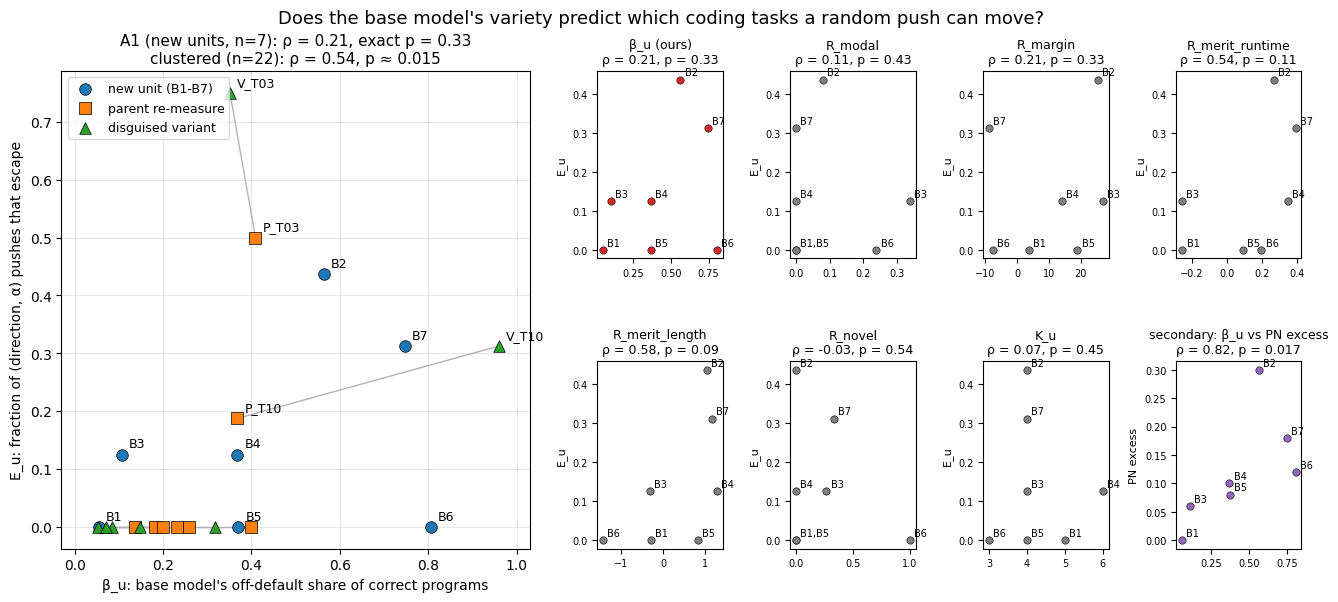

In [20]:
vals = res_ext["values"]
kinds = {"new": ("o", "new unit (B1-B7)", "tab:blue"), "P_": ("s", "parent re-measure", "tab:orange"),
         "V_": ("^", "disguised variant", "tab:green")}
kind_of = lambda u: u[:2] if u[:2] in ("P_", "V_") else "new"  # noqa: E731

fig = plt.figure(figsize=(16, 6.2))
gs = fig.add_gridspec(2, 6, width_ratios=[1.6, 1.6, 1, 1, 1, 1], wspace=0.45, hspace=0.55)
ax = fig.add_subplot(gs[:, :2])
for t in sorted({u[2:] for u in vals if kind_of(u) != "new"}):
    if f"P_{t}" in vals and f"V_{t}" in vals:
        ax.plot([vals[f"P_{t}"]["beta"], vals[f"V_{t}"]["beta"]], [vals[f"P_{t}"]["E"], vals[f"V_{t}"]["E"]],
                color="0.7", lw=1, zorder=1)
for kd, (mk, lab, col) in kinds.items():
    us = [u for u in vals if kind_of(u) == kd]
    ax.scatter([vals[u]["beta"] for u in us], [vals[u]["E"] for u in us], marker=mk, s=70, color=col,
               edgecolors="black", linewidths=0.5, label=lab, zorder=3)
    for u in us:
        if kd == "new" or vals[u]["E"] > 0:
            ax.annotate(u, (vals[u]["beta"], vals[u]["E"]), textcoords="offset points", xytext=(5, 5), fontsize=9)
ax.set_xlabel("β_u: base model's off-default share of correct programs")
ax.set_ylabel("E_u: fraction of (direction, α) pushes that escape")
ax.set_title(f"A1 (new units, n=7): ρ = {r1['primary']['rho']:.2f}, exact p = {r1['primary']['p']:.2f}\n"
             f"clustered (n=22): ρ = {res_ext['clustered_all']['rho']:.2f}, p ≈ {res_ext['clustered_all']['p']:.3f}",
             fontsize=11)
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(-0.03, 1.03)

E_new = {x["unit"]: x["E_u"] for x in units}
panels = [("β_u (ours)", {x["unit"]: x["beta_u"] for x in units}, r1["primary"])]
panels += [(name, r1["rivals"][name]["values"], {"rho": r1["rivals"][name]["rho_rival_E"], "p": r1["rivals"][name]["p_rival"]})
           for name in ("R_modal", "R_margin", "R_merit_runtime", "R_merit_length", "R_novel", "K_u")]
for i, (name, xs, st) in enumerate(panels):
    a = fig.add_subplot(gs[i // 4, 2 + i % 4])
    us = [u for u in xs if u in E_new]
    a.scatter([xs[u] for u in us], [E_new[u] for u in us], s=28, color="tab:red" if i == 0 else "tab:gray",
              edgecolors="black", linewidths=0.4)
    at = {}
    for u in us:
        at.setdefault((xs[u], E_new[u]), []).append(u)
    for (px, py), names in at.items():
        a.annotate(",".join(names), (px, py), textcoords="offset points", xytext=(3, 3), fontsize=7)
    a.set_title(f"{name}\nρ = {st['rho']:.2f}, p = {st['p']:.2f}", fontsize=9)
    a.tick_params(labelsize=7)
    a.set_ylabel("E_u", fontsize=8)
a = fig.add_subplot(gs[1, 5])
pn = {x["unit"]: x["PN_excess_u"] for x in units}
a.scatter([x["beta_u"] for x in units], [pn[x["unit"]] for x in units], s=28, color="tab:purple",
          edgecolors="black", linewidths=0.4)
for x in units:
    a.annotate(x["unit"], (x["beta_u"], pn[x["unit"]]), textcoords="offset points", xytext=(3, 3), fontsize=7)
a.set_title(f"secondary: β_u vs PN excess\nρ = {r1['secondary_PN']['rho']:.2f}, p = {r1['secondary_PN']['p']:.3f}",
            fontsize=9)
a.set_ylabel("PN excess", fontsize=8)
a.tick_params(labelsize=7)
fig.suptitle("Does the base model's variety predict which coding tasks a random push can move?", fontsize=13)
plt.show()

### Figure 2: where the pushes escaped

Rows are units and columns are the 16 (α, direction) cells. The colour is the stage-1 excess: the off-default share minus the twin's. ● marks a confirmed escape and ○ a stage-1 pass that was not confirmed. P_t and V_t rows share their parent's 8 directions, so their columns are directly comparable.

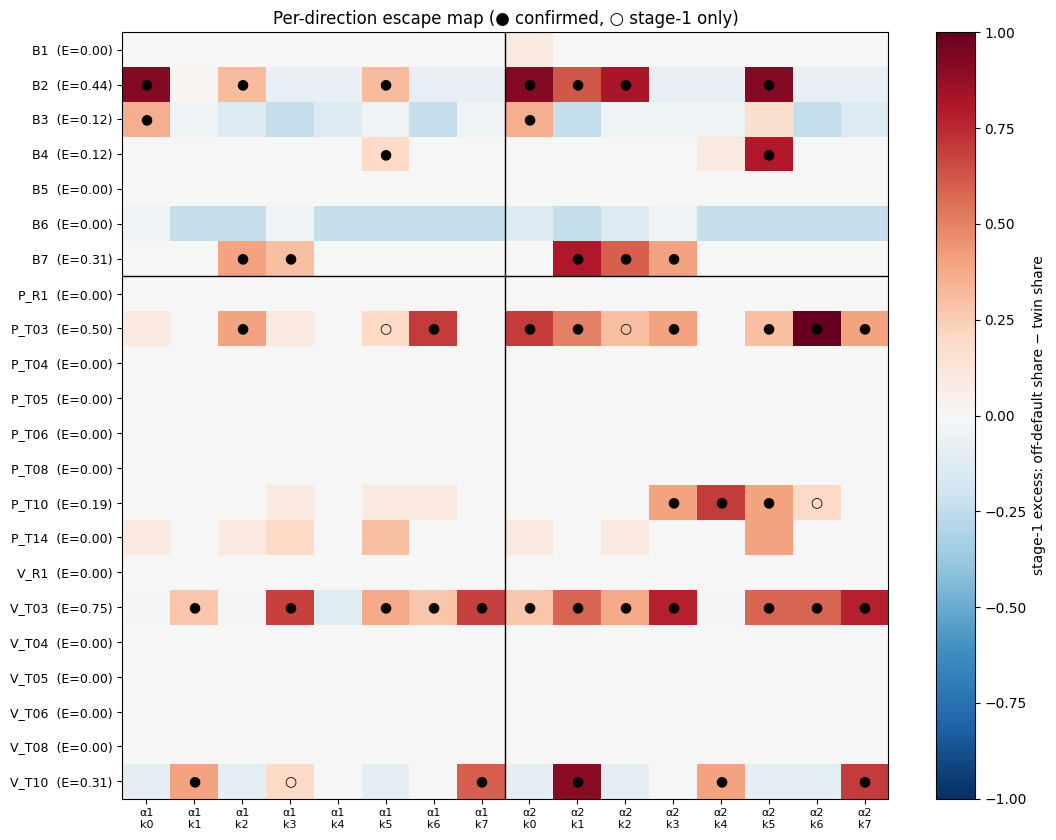

In [21]:
order = [x["unit"] for x in units] + [u for u in sorted(vals) if kind_of(u) != "new"]
mat = np.full((len(order), 2 * N_DIRS), np.nan)
marks = []
for i, u in enumerate(order):
    k_of = {direction_seed(u, k): k for k in range(N_DIRS)}
    for c in BY_UNIT[u]["metadata_per_direction"]:
        j = (0 if c["alpha"] == 1.0 else N_DIRS) + k_of[c["seed"]]
        mat[i, j] = np.nan if c["excess_stage1"] is None else c["excess_stage1"]
        if c["confirmed"] or c["stage1_passed"]:
            marks.append((i, j, "●" if c["confirmed"] else "○"))
lim = np.nanmax(np.abs(mat))
fig, ax = plt.subplots(figsize=(11, 8.5))
im = ax.imshow(mat, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i, j, s in marks:
    ax.text(j, i, s, ha="center", va="center", fontsize=10, color="black")
ax.set_xticks(range(2 * N_DIRS))
ax.set_xticklabels([f"α{int(a)}\nk{k}" for a in ALPHAS for k in range(N_DIRS)], fontsize=8)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{u}  (E={TAB[u]['E_u']:.2f})" for u in order], fontsize=9)
ax.axvline(N_DIRS - 0.5, color="black", lw=1)
ax.axhline(len(units) - 0.5, color="black", lw=1)
fig.colorbar(im, ax=ax, label="stage-1 excess: off-default share − twin share")
ax.set_title("Per-direction escape map (● confirmed, ○ stage-1 only)", fontsize=12)
plt.tight_layout()
plt.show()

### Figure 3: where escaping pushes land (A2)

For each A2 event (a movable new unit), the bars compare the base model's distribution over the surviving (non-default) algorithms with the distribution of correct off-default programs produced by confirmed pushes. A2 asks whether the tallest bars coincide.

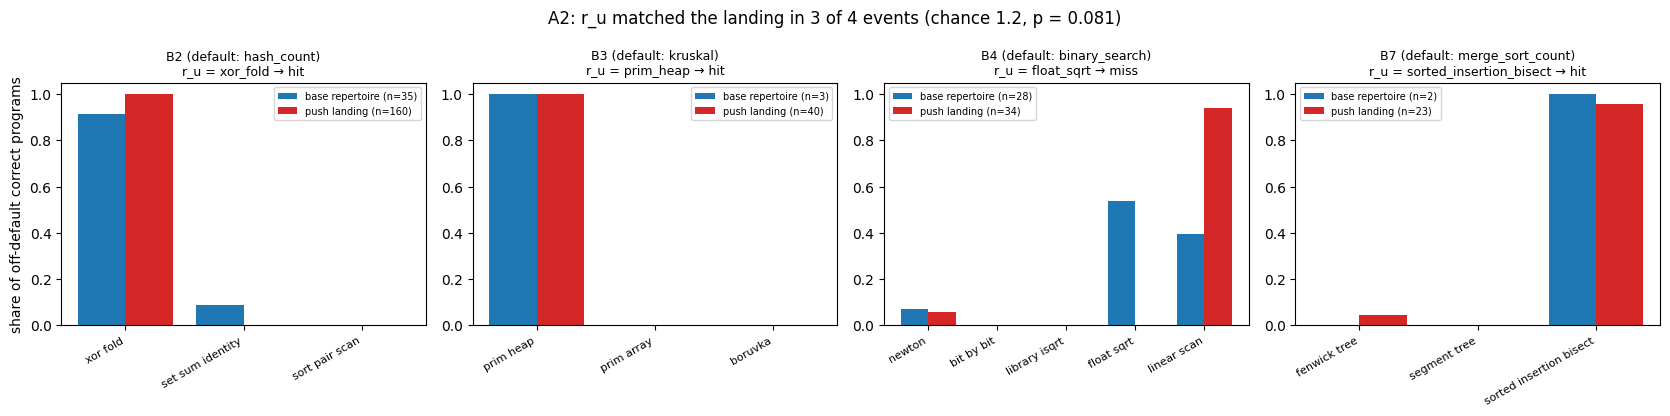

In [22]:
evs = r2["events"]
fig, axes = plt.subplots(1, len(evs), figsize=(4.2 * len(evs), 4.2), squeeze=False)
for ax, e in zip(axes[0], evs):
    r = BY_UNIT[e["unit"]]
    d = r["output"]
    surv = [m for m in r["metadata_catalogue"] if m != d]
    bc = {k: v for k, v in r["metadata_base_correct_composition"].items() if k in surv}
    lc = e["landing_composition"]
    tb, tl = max(sum(bc.values()), 1), max(sum(lc.values()), 1)
    xs = np.arange(len(surv))
    ax.bar(xs - 0.2, [bc.get(s, 0) / tb for s in surv], 0.4, label=f"base repertoire (n={sum(bc.values())})",
           color="tab:blue")
    ax.bar(xs + 0.2, [lc.get(s, 0) / tl for s in surv], 0.4, label=f"push landing (n={sum(lc.values())})",
           color="tab:red")
    ax.set_xticks(xs)
    ax.set_xticklabels([s.replace("_", " ") for s in surv], rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{e['unit']} (default: {d})\nr_u = {e['r_u']} → {'hit' if e['hit'] else 'miss'}", fontsize=9)
    ax.legend(fontsize=7, loc="best")
axes[0][0].set_ylabel("share of off-default correct programs")
fig.suptitle(f"A2: r_u matched the landing in {r2['top1']['hits']:.0f} of {r2['top1']['n']} events "
             f"(chance {r2['top1']['expected_by_chance']:.1f}, p = {r2['top1']['poisson_binomial_p']:.3f})", fontsize=12)
plt.tight_layout()
plt.show()

### Figure 4: the push itself, wording changes, and repertoire breadth

- **(a)** Cosine similarity of B2's 8 push directions in the 4096-d residual space. They are nearly orthogonal, so the 8 directions sample independent ways to nudge.
- **(b)** How far the push moves the hidden state at each edited block, as a fraction of the hidden-state norm (α · r_Q(l)).
- **(c)** Within-parent Δβ against ΔE: rewording a task as a narrative changes β and E, sometimes together with the default (labelled).
- **(d)** The effective number of correct algorithms (rarefied Hill-1, 25 programs) in the base repertoire vs under plan noise, per new unit.

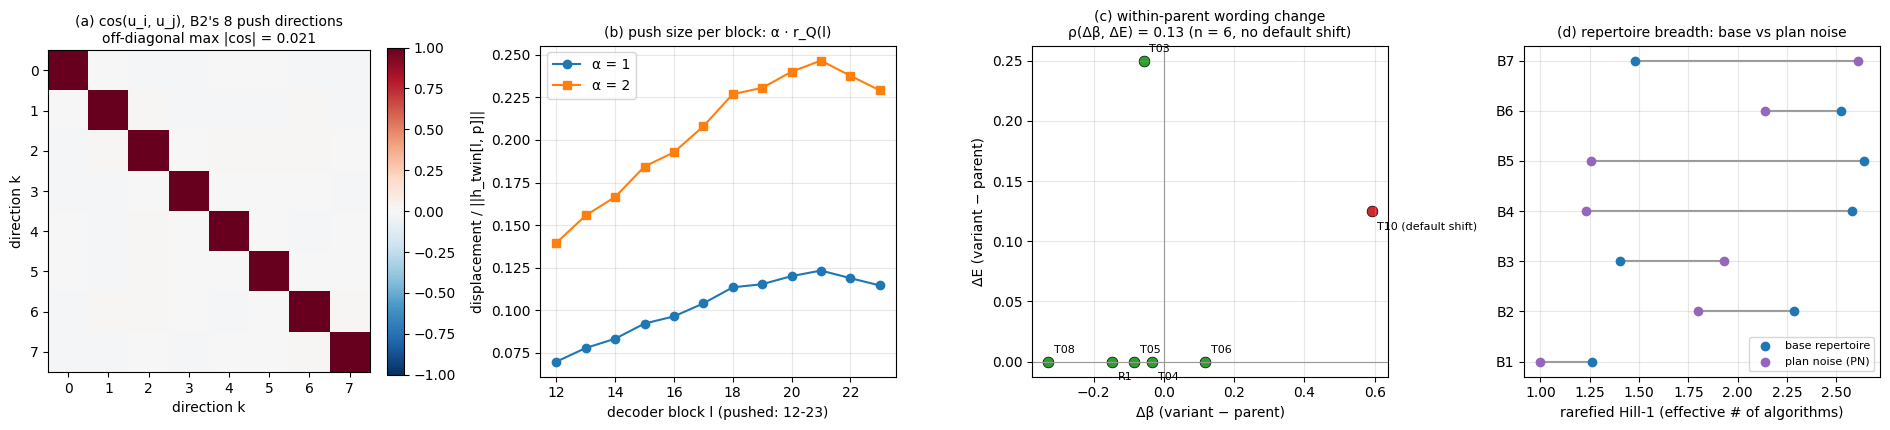

In [23]:
fig, axs = plt.subplots(1, 4, figsize=(19, 4.4))
ax = axs[0]
im = ax.imshow(cos, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(N_DIRS))
ax.set_yticks(range(N_DIRS))
ax.set_xlabel("direction k")
ax.set_ylabel("direction k")
ax.set_title(f"(a) cos(u_i, u_j), B2's 8 push directions\noff-diagonal max |cos| = {np.abs(cos - np.eye(N_DIRS)).max():.3f}",
             fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046)

ax = axs[1]
for a, mk in zip(ALPHAS, ("o-", "s-")):
    ax.plot(EDIT_BLOCKS, [a * r_at(l) for l in EDIT_BLOCKS], mk, label=f"α = {a:.0f}")
ax.set_xlabel("decoder block l (pushed: 12-23)")
ax.set_ylabel("displacement / ||h_twin[l, p]||")
ax.set_title("(b) push size per block: α · r_Q(l)", fontsize=10)
ax.legend()
ax.grid(alpha=0.3)

ax = axs[2]
pts = sorted([p for p in out_var["pairs"] if p["delta_beta"] is not None], key=lambda p: (p["delta_E"], p["delta_beta"]))
for i, p in enumerate(pts):   # labels alternate above / below so neighbouring pairs stay readable
    col = "tab:red" if p["default_shift"] else "tab:green"
    ax.scatter(p["delta_beta"], p["delta_E"], s=60, color=col, edgecolors="black", linewidths=0.5)
    ax.annotate(p["parent"] + (" (default shift)" if p["default_shift"] else ""), (p["delta_beta"], p["delta_E"]),
                textcoords="offset points", xytext=(4, 6 if i % 2 == 0 else -13), fontsize=8)
ax.axhline(0, color="0.6", lw=0.8)
ax.axvline(0, color="0.6", lw=0.8)
ax.set_xlabel("Δβ (variant − parent)")
ax.set_ylabel("ΔE (variant − parent)")
ax.set_title(f"(c) within-parent wording change\nρ(Δβ, ΔE) = {out_var['spearman_delta_beta_delta_E']['rho']:.2f} "
             f"(n = {out_var['n_pairs_no_default_shift']}, no default shift)", fontsize=10)
ax.grid(alpha=0.3)

ax = axs[3]
us = [x["unit"] for x in units]
hb = [BY_UNIT[u]["metadata_repertoire"]["base_hill1_rarefied"] for u in us]
hp = [BY_UNIT[u]["metadata_repertoire"]["pn_hill1_rarefied"] for u in us]
ys = np.arange(len(us))
for y, a_, b_ in zip(ys, hb, hp):
    ax.plot([a_, b_], [y, y], color="0.6", zorder=1)
ax.scatter(hb, ys, color="tab:blue", label="base repertoire", zorder=3)
ax.scatter(hp, ys, color="tab:purple", label="plan noise (PN)", zorder=3)
ax.set_yticks(ys)
ax.set_yticklabels(us)
ax.set_xlabel("rarefied Hill-1 (effective # of algorithms)")
ax.set_title("(d) repertoire breadth: base vs plan noise", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Take-aways

- **A1 is not supported within panel B.** ρ(β_u, E_u) = 0.21, exact p = 0.33, n = 7. The clearest counter-example is **B6** (valid anagram): the base model is very diverse (β = 0.81), yet no push escaped the instruct default. All seven units have β ≥ 0.05, so the "collapsed → immovable" half of the claim is **untested** here. The decisive test pools panels A and B (`pooled_inputs.json`).
- **Plan noise tracks β much better:** ρ(β_u, PN excess) = 0.82 (p = 0.017). Read descriptively (n = 7), a *fresh* random direction per sample seems to expose the base model's variety more faithfully than 8 fixed directions do.
- **A2, where pushes land:** in 3 of 4 movable units the push landed on r_u, the base model's favourite alternative (chance 1.2, p = 0.081). The base-composition forecast beat association answers by +0.68 nats per event and AST proximity by +0.13.
- **Wider descriptive views** agree in sign: ρ = 0.43 for new units + parents (n = 15) and a cluster-preserving ρ = 0.54 (p ≈ 0.015, n = 22). Within parents, only T03 and T10 move; T10's rewording also shifted the default.
- **In layman's terms:** random internal nudges *can* move Qwen3-8B to a different **correct** algorithm on some tasks (B2, B7, B3, B4, T03, T10). When they do, they mostly land on an algorithm the base model already favoured. The nudge re-weights existing options rather than producing new ones; the artifact's novelty audit, not re-run here, found 0 novel algorithms among 10,366 correct programs.